### Week 9 notebook - Gradient Boosting, Mod C Data Science Capstone Fall 2026
### By Shuqin Ouyang

# Student dataset analysis starts here:

In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, train_test_split, GridSearchCV, validation_curve
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.inspection import permutation_importance

In [2]:
# same shuffled 5-fold CV as Weeks 6 and 8
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# boosting model (max_iter = number of trees): many small trees, each one fits the errors left by the trees before it.
# early_stopping=False so it always builds exactly max_iter trees. Defaults: min_samples_leaf=20, l2_regularization=0 (no regularization)
# max_bins=64 (default 255) groups feature values into fewer bins, about 1.5x faster with little effect on accuracy
BOOST = HistGradientBoostingClassifier(early_stopping=False, max_bins=64, random_state=42)

GRID = {'learning_rate': [0.1, 0.3], 'max_iter': [50, 100, 200], 'max_depth': [2, 4, 8]}    # max_iter = number of trees
MULTIPLES = [0.25, 0.5, 1, 2, 4]    # how far to move each best setting: a quarter, half, same, double, four times
LABELS = ['1/4x', '1/2x', '1x', '2x', '4x']
GRID_REG = {'min_samples_leaf': [5, 20, 100, 300], 'l2_regularization': [0, 1, 10]}    # regularization: bigger leaves, penalty on leaf values

Helper functions (used for both datasets):

In [3]:
def split_data(df, target):
    # same as Weeks 5, 6 and 8: stratified 80/20 split
    df = df.dropna()
    return train_test_split(df.drop(columns=[target]), df[target], test_size=0.2, stratify=df[target], random_state=42)

def results(grid):
    # one row per setting tried: its parameters, CV F1, train F1 and the gap between them (overfitting)
    res = pd.DataFrame(grid.cv_results_['params'])
    res['CV F1'], res['train F1'] = grid.cv_results_['mean_test_score'], grid.cv_results_['mean_train_score']
    res['gap'] = res['train F1'] - res['CV F1']
    return res

def plot_pair(cv, gap, title, hline=None, hline_label=''):
    # left: CV F1 (dashed line = a reference), right: train F1 - CV F1 (overfitting). One line per column
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    cv.plot(ax=axes[0], marker='o', ylabel='CV F1', title=title)
    gap.plot(ax=axes[1], marker='o', ylabel='train F1 - CV F1', title='overfitting gap')
    if hline is not None:
        axes[0].axhline(hline, color='gray', linestyle='--', label=hline_label)
    for ax in axes:
        ax.legend(title=cv.columns.name, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4)
    plt.tight_layout()
    plt.show()

Dataset 1 background quick overview:

The dataset 1 used is the Taiwanese Bankruptcy Prediction dataset from UCI, link as https://archive.ics.uci.edu/dataset/572/taiwanese+bankruptcy+prediction.
It contains company financial indicators and a binary outcome for bankruptcy.

In [4]:
# install uci package so can load the data using package
# install once in terminal or notebook

!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# load dataset from UCI repository using dataset id
data_bankruptcy = fetch_ucirepo(id=572)

df_bankruptcy = pd.concat(
    [data_bankruptcy.data.features.copy(),
     data_bankruptcy.data.targets.copy()],
    axis=1
)

# remove leading/trailing spaces from column names once, here
df_bankruptcy.columns = df_bankruptcy.columns.str.strip()

df_bankruptcy.head()

'pip' is not recognized as an internal or external command,
operable program or batch file.


,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),...,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability,Bankrupt?
0,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,...,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469,1
1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,...,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794,1
2,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,0.780284,...,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474,1
3,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,0.781241,...,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982,1
4,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,0.781550,...,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490,1


Student markdown:

Dataset 1 is the Taiwanese bankruptcy data: 6,819 companies described by 95 financial ratios, of which about 3.2% went bankrupt. All features are numeric and none are missing.

In [5]:
# stratified 80/20 split, all features. Same split as Weeks 5, 6 and 8
X_train_bankrupt, X_test_bankrupt, y_train_bankrupt, y_test_bankrupt = split_data(df_bankruptcy, 'Bankrupt?')
p_bankrupt = y_test_bankrupt.mean()
print(len(X_train_bankrupt), "train rows,", len(X_test_bankrupt), "test rows. baseline F1 (predict every company fails):", round(2 * p_bankrupt / (1 + p_bankrupt), 3))

5455 train rows, 1364 test rows. baseline F1 (predict every company fails): 0.062


Student markdown:

I use the same stratified 80/20 split as Weeks 5, 6 and 8 (5,455 training and 1,364 test rows), and predicting every company fails would score F1 0.062. Boosting builds small trees one after another, each fitting the errors left by the earlier ones. Trees only compare values to cut-offs, so unlike KNN no scaling or outlier capping is needed. The settings tuned are the learning rate (how much of each tree is added), the number of trees and the depth, then regularization (minimum rows per leaf and an l2 penalty on the leaf values).

Step 1: let the search choose. Grid search tries every combination of learning rate (how much of each tree is added), number of trees (max_iter) and tree depth, and keeps the best CV F1. Regularization is left out for now.

best: {'learning_rate': 0.1, 'max_depth': 8, 'max_iter': 100} | CV F1 0.353 | train F1 1.0
 learning_rate  max_depth  max_iter  CV F1  train F1   gap
           0.1          2        50  0.241     0.453 0.212
           0.1          2       100  0.288     0.612 0.325
           0.1          2       200  0.321     0.808 0.486
           0.1          4        50  0.282     0.862 0.580
           0.1          4       100  0.332     0.994 0.662
           0.1          4       200  0.311     1.000 0.689
           0.1          8        50  0.344     1.000 0.656
           0.1          8       100  0.353     1.000 0.647
           0.1          8       200  0.303     1.000 0.697
           0.3          2        50  0.287     0.724 0.437
           0.3          2       100  0.334     0.942 0.608
           0.3          2       200  0.337     1.000 0.663
           0.3          4        50  0.317     1.000 0.683
           0.3          4       100  0.338     1.000 0.662
           0.3          

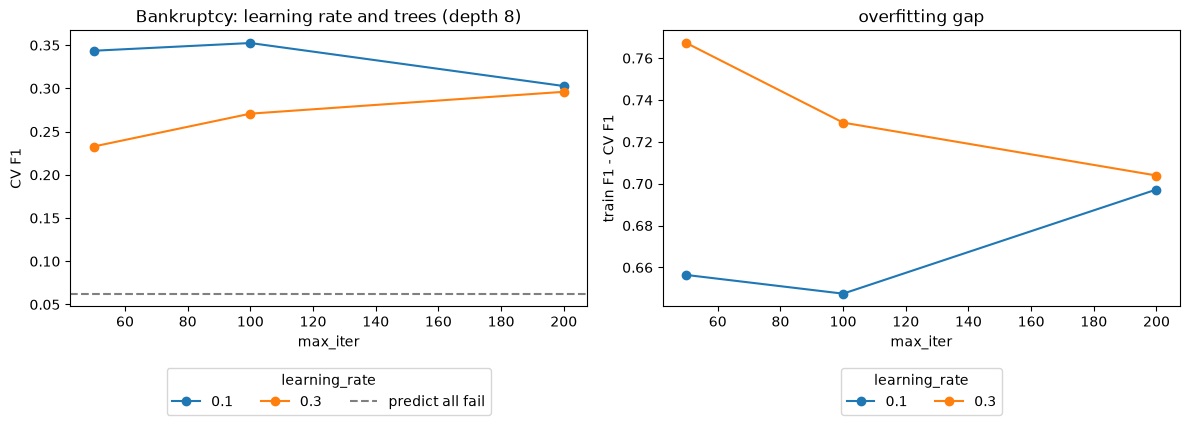

In [6]:
grid_bankrupt = GridSearchCV(BOOST, GRID, cv=CV, scoring='f1', return_train_score=True, n_jobs=-1).fit(X_train_bankrupt, y_train_bankrupt)
best_bankrupt = grid_bankrupt.best_params_
res_bankrupt = results(grid_bankrupt)
print("best:", best_bankrupt, "| CV F1", round(grid_bankrupt.best_score_, 3), "| train F1", round(res_bankrupt.loc[grid_bankrupt.best_index_, 'train F1'], 3))
print(res_bankrupt.round(3).to_string(index=False))
print("CV std of the best setting:", round(grid_bankrupt.cv_results_['std_test_score'][grid_bankrupt.best_index_], 3))
shallow_bankrupt = res_bankrupt[res_bankrupt.max_depth == best_bankrupt['max_depth']]    # charts at the best depth
plot_pair(shallow_bankrupt.pivot(index='max_iter', columns='learning_rate', values='CV F1'), shallow_bankrupt.pivot(index='max_iter', columns='learning_rate', values='gap'),
          'Bankruptcy: learning rate and trees (depth ' + str(best_bankrupt['max_depth']) + ')', 2 * p_bankrupt / (1 + p_bankrupt), 'predict all fail')

Student markdown:

The best setting is learning rate 0.1, depth 8 and 100 trees: CV F1 0.353 (baseline 0.062) with train F1 1.0, so the model memorizes the training data (gap 0.647). Train F1 is 1.0 or close in most settings with depth 4 or 8, because boosting keeps fitting the remaining errors and there are few failures to memorize. The search picks this setting only because it has the highest CV F1, and less-fit settings score lower (depth 2 with 50 trees: 0.241). The CV std is large (0.09), so the table is flat within it: depth 4 with learning rate 0.3 and 200 trees scores 0.352 and depth 2 reaches 0.337. At depth 8, learning rate 0.1 peaks at 100 trees (0.344, 0.353 and 0.303 for 50, 100 and 200 trees), while 0.3 scores lower (0.233, 0.271 and 0.296). A faster rate of 0.3 is close to the best only at depth 4.

Hypothesis A: overfitting grows with more trees and deeper trees. Each best setting is moved to a quarter, half, double and four times its value, one at a time. The tables show how much CV F1 moves for each setting, then CV F1 and the gap between train and CV F1 at each step.

In [7]:
# one setting at a time moves to a quarter, half, double and four times its best value, the other two stay at their best
sweep_cv_bankrupt, sweep_gap_bankrupt = {}, {}
for setting, value in best_bankrupt.items():
    values = [value * m if setting == 'learning_rate' else max(1, round(value * m)) for m in MULTIPLES]
    train, test = validation_curve(clone(BOOST).set_params(**best_bankrupt), X_train_bankrupt, y_train_bankrupt, param_name=setting, param_range=values, cv=CV, scoring='f1', n_jobs=-1)
    sweep_cv_bankrupt[setting], sweep_gap_bankrupt[setting] = test.mean(axis=1), train.mean(axis=1) - test.mean(axis=1)
sweep_cv_bankrupt, sweep_gap_bankrupt = pd.DataFrame(sweep_cv_bankrupt, index=LABELS), pd.DataFrame(sweep_gap_bankrupt, index=LABELS)
print("how much CV F1 moves (highest minus lowest) when each setting changes:")
print((sweep_cv_bankrupt.max() - sweep_cv_bankrupt.min()).round(3))
print("CV F1 at each multiple of the best value:")
print(sweep_cv_bankrupt.round(3))
print("overfitting gap (train F1 - CV F1):")
print(sweep_gap_bankrupt.round(3))

how much CV F1 moves (highest minus lowest) when each setting changes:
learning_rate    0.125
max_depth        0.080
max_iter         0.074
dtype: float64
CV F1 at each multiple of the best value:
      learning_rate  max_depth  max_iter
1/4x          0.227      0.288     0.279
1/2x          0.306      0.332     0.344
1x            0.353      0.353     0.353
2x            0.270      0.297     0.303
4x            0.268      0.273     0.326
overfitting gap (train F1 - CV F1):
      learning_rate  max_depth  max_iter
1/4x          0.759      0.325     0.707
1/2x          0.694      0.662     0.656
1x            0.647      0.647     0.647
2x            0.730      0.703     0.697
4x            0.585      0.727     0.674


Student markdown:

The best setting (1x) has the highest CV F1 (0.353) because the search chose it, and its neighbors are lower, so the first search already lands close to the answer. The learning rate moves CV F1 the most (0.125, down to 0.227 at a quarter of 0.1), then depth (0.080) and trees (0.074). With a CV std of 0.09 only the learning rate change is bigger than the noise, so the ranking is a hint. Since only two learning rates were in the grid, the learning rate is the setting most worth tuning more finely. Deeper than 8 does not help (0.297 at depth 16 and 0.273 at 32). The gap does not clearly grow with more trees or depth, because it is already 0.647 at the best setting and stays between 0.585 and 0.759 almost everywhere. The exception is depth 2, with a gap of 0.325 and CV F1 0.288, so shallow trees overfit less without scoring clearly better.

Hypothesis B: regularization shrinks the gap between train and CV F1, but may not raise F1. The search tries the minimum rows in a leaf (bigger leaves cannot fit a few rows) and an l2 penalty. L2 shrinks each leaf's output toward zero, and shrinks small leaves the most because they have the weakest evidence, so each tree adds a gentler correction. The first table compares the best found with the default model (leaf 20, l2 0, which already has a small leaf limit), and the second lists all 12 combinations.

In [8]:
# regularization on top of the best Step 1 setting. (leaf 20, l2 0) is the model without regularization
grid_reg_bankrupt = GridSearchCV(clone(BOOST).set_params(**best_bankrupt), GRID_REG, cv=CV, scoring='f1', return_train_score=True, n_jobs=-1).fit(X_train_bankrupt, y_train_bankrupt)
reg_bankrupt = results(grid_reg_bankrupt)
none_bankrupt = reg_bankrupt[(reg_bankrupt.min_samples_leaf == 20) & (reg_bankrupt.l2_regularization == 0)].index[0]
print(reg_bankrupt.loc[[none_bankrupt, grid_reg_bankrupt.best_index_]].assign(model=['no regularization', 'best found']).set_index('model').round(3))
print(reg_bankrupt.round(3).to_string(index=False))
print("CV std of the best setting:", round(grid_reg_bankrupt.cv_results_['std_test_score'][grid_reg_bankrupt.best_index_], 3))

                   l2_regularization  min_samples_leaf  CV F1  train F1    gap
model                                                                         
no regularization                  0                20  0.353       1.0  0.647
best found                         0                20  0.353       1.0  0.647
 l2_regularization  min_samples_leaf  CV F1  train F1   gap
                 0                 5  0.276     1.000 0.724
                 0                20  0.353     1.000 0.647
                 0               100  0.330     1.000 0.670
                 0               300  0.331     0.914 0.583
                 1                 5  0.273     1.000 0.727
                 1                20  0.289     1.000 0.711
                 1               100  0.351     1.000 0.649
                 1               300  0.318     0.862 0.544
                10                 5  0.303     0.991 0.688
                10                20  0.268     0.986 0.719
                10      

Student markdown:

The best found is the default (leaf 20, l2 0, CV F1 0.353), and leaf 100 with l2 1 ties at 0.351. All 12 combinations fall between 0.268 and 0.353, less than the CV std of 0.09, so regularization shows no clear effect on F1. It does shrink the gap (0.647 to 0.583 with leaf 300 and l2 0, and to 0.380 with leaf 300 and l2 10), but only because train F1 falls (1.0 to 0.685) while CV F1 stays about the same (0.305). A leaf of 100 rows would hold few failures here (about 3% of rows), which is probably why large leaves do not help, though I did not test this. The final model keeps the defaults and still has train F1 1.0, so regularization did not fix the overfit.

In [9]:
# final model: the best regularization search result (already refit on the training set), tested once on the held-out 20%
model_bankrupt = grid_reg_bankrupt.best_estimator_
pred_bankrupt = model_bankrupt.predict(X_test_bankrupt)
final_bankrupt = pd.Series({**best_bankrupt, **grid_reg_bankrupt.best_params_, 'CV F1': grid_reg_bankrupt.best_score_,
                         'test F1': f1_score(y_test_bankrupt, pred_bankrupt), 'precision': precision_score(y_test_bankrupt, pred_bankrupt),
                         'recall': recall_score(y_test_bankrupt, pred_bankrupt), 'F1 if all predicted fail': 2 * p_bankrupt / (1 + p_bankrupt)})
print(final_bankrupt)

learning_rate                 0.100000
max_depth                     8.000000
max_iter                    100.000000
l2_regularization             0.000000
min_samples_leaf             20.000000
CV F1                         0.352525
test F1                       0.349206
precision                     0.578947
recall                        0.250000
F1 if all predicted fail      0.062500
dtype: float64


In [10]:
# top 10 features by permutation importance (shuffle one feature, see how much test F1 drops)
imp_bankrupt = permutation_importance(model_bankrupt, X_test_bankrupt, y_test_bankrupt, scoring='f1', n_repeats=2, random_state=42)
features_bankrupt = pd.Series(imp_bankrupt.importances_mean, index=X_test_bankrupt.columns).nlargest(10).round(4)
print(features_bankrupt)

Continuous interest rate (after tax)                 0.1617
Total debt/Total net worth                           0.1395
Quick Ratio                                          0.1270
ROA(B) before interest and depreciation after tax    0.0943
Persistent EPS in the Last Four Seasons              0.0634
Debt ratio %                                         0.0353
Interest-bearing debt interest rate                  0.0279
Quick Asset Turnover Rate                            0.0266
Working capitcal Turnover Rate                       0.0186
Net Income to Total Assets                           0.0155
dtype: float64


Student markdown:

The final model (learning rate 0.1, depth 8, 100 trees, leaf 20, l2 0) reaches test F1 0.349 (precision 0.579, recall 0.250) against the 0.062 baseline, about 5.6 times better and close to its CV F1 of 0.353. So the overfit (train F1 1.0) did not hurt on new data. It finds about 1 in 4 failures and is right about 6 times in 10 when it flags one. The test set has only about 44 failures (about 3% of 1,364 rows), so this number is noisy. Permutation importance ranks Continuous interest rate (after tax) first (0.162), then Total debt/Total net worth (0.140), Quick Ratio (0.127), ROA(B) before interest and depreciation after tax (0.094) and Persistent EPS in the Last Four Seasons (0.063), and the rest are 0.036 or less.

Expected: the learning rate matters most, and the top features are interest, debt, liquidity and earnings ratios. Unexpected: train F1 of 1.0, and that tuning and regularization ended at the defaults (leaf 20, l2 0) with the same CV F1. This shows a limit of boosting: without control it can fit the training data exactly, and this model overfits easily. The EDA that helped was the 3% failure rate (the baseline and the low recall). The grid is small (2 learning rates, 3 tree counts, 3 depths), so part of the flatness may come from the few choices.

Dataset 2 background quick overview:

The dataset 2 used is the Default of Credit Card Clients dataset from UCI, link as https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients.

It contains demographic information, credit limits, repayment history, bill statements, and previous payment records for Taiwanese credit card clients, along with a binary outcome indicating whether the client defaulted on the next payment.

In [11]:
# UCI dataset already decides features and targets already, but still need to look into details / verify to make sure all ok
data_credit = fetch_ucirepo(id=350)

df_credit = pd.concat(
    [data_credit.data.features.copy(),
     data_credit.data.targets.copy()],
    axis=1
)

df_credit.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [12]:
# columns rename for easier reading

df_credit = df_credit.rename(columns={

    "Y": "default_next_month",

    "X1": "credit_limit",
    "X2": "gender",
    "X3": "education",
    "X4": "marital_status",
    "X5": "age",

    "X6": "repay_2005_sep",
    "X7": "repay_2005_aug",
    "X8": "repay_2005_jul",
    "X9": "repay_2005_jun",
    "X10": "repay_2005_may",
    "X11": "repay_2005_apr",

    "X12": "bill_2005_sep",
    "X13": "bill_2005_aug",
    "X14": "bill_2005_jul",
    "X15": "bill_2005_jun",
    "X16": "bill_2005_may",
    "X17": "bill_2005_apr",

    "X18": "pay_2005_sep",
    "X19": "pay_2005_aug",
    "X20": "pay_2005_jul",
    "X21": "pay_2005_jun",
    "X22": "pay_2005_may",
    "X23": "pay_2005_apr"
})

df_credit.head()

,credit_limit,gender,education,marital_status,age,repay_2005_sep,repay_2005_aug,repay_2005_jul,repay_2005_jun,repay_2005_may,...,bill_2005_jun,bill_2005_may,bill_2005_apr,pay_2005_sep,pay_2005_aug,pay_2005_jul,pay_2005_jun,pay_2005_may,pay_2005_apr,default_next_month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Student markdown:

Dataset 2 is the credit card default data: 30,000 clients described by 23 features (credit limit, demographics, six months of repayment status, bill amounts and payments), of which about 22% default next month. No values are missing.

In [13]:
# stratified 80/20 split, all features. Same split as Weeks 5, 6 and 8
X_train_credit, X_test_credit, y_train_credit, y_test_credit = split_data(df_credit, 'default_next_month')
p_credit = y_test_credit.mean()
print(len(X_train_credit), "train rows,", len(X_test_credit), "test rows. baseline F1 (predict every client defaults):", round(2 * p_credit / (1 + p_credit), 3))

24000 train rows, 6000 test rows. baseline F1 (predict every client defaults): 0.362


Student markdown:

The split is the same as before (24,000 training and 6,000 test rows), and predicting every client defaults would score F1 0.362. As for bankruptcy, trees need no scaling or capping.

Step 1: let the search choose, same as for bankruptcy.

best: {'learning_rate': 0.1, 'max_depth': 8, 'max_iter': 100} | CV F1 0.484 | train F1 0.556
 learning_rate  max_depth  max_iter  CV F1  train F1   gap
           0.1          2        50  0.470     0.474 0.003
           0.1          2       100  0.474     0.480 0.007
           0.1          2       200  0.475     0.485 0.010
           0.1          4        50  0.476     0.493 0.017
           0.1          4       100  0.477     0.509 0.032
           0.1          4       200  0.480     0.532 0.052
           0.1          8        50  0.481     0.523 0.042
           0.1          8       100  0.484     0.556 0.072
           0.1          8       200  0.482     0.630 0.148
           0.3          2        50  0.476     0.484 0.009
           0.3          2       100  0.478     0.490 0.012
           0.3          2       200  0.478     0.502 0.024
           0.3          4        50  0.475     0.523 0.048
           0.3          4       100  0.473     0.558 0.085
           0.3        

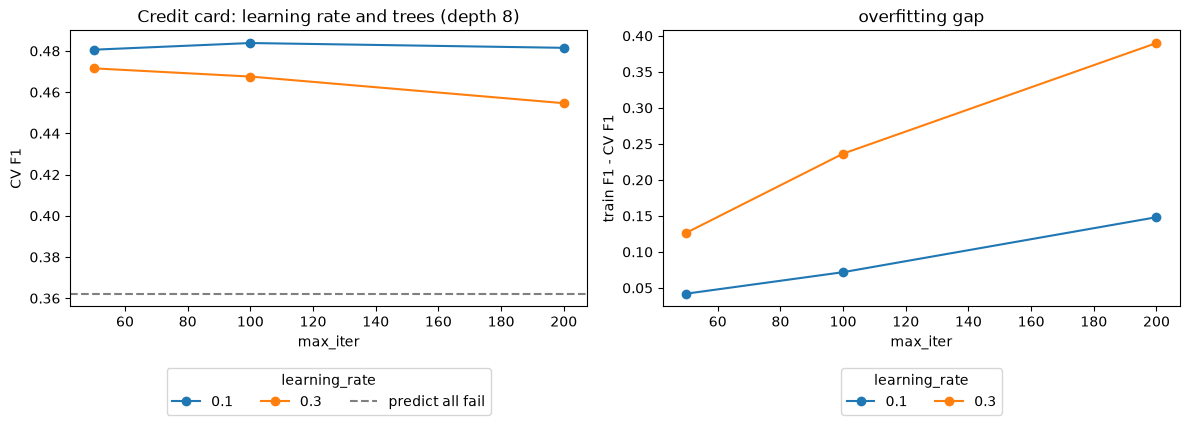

In [14]:
grid_credit = GridSearchCV(BOOST, GRID, cv=CV, scoring='f1', return_train_score=True, n_jobs=-1).fit(X_train_credit, y_train_credit)
best_credit = grid_credit.best_params_
res_credit = results(grid_credit)
print("best:", best_credit, "| CV F1", round(grid_credit.best_score_, 3), "| train F1", round(res_credit.loc[grid_credit.best_index_, 'train F1'], 3))
print(res_credit.round(3).to_string(index=False))
print("CV std of the best setting:", round(grid_credit.cv_results_['std_test_score'][grid_credit.best_index_], 3))
shallow_credit = res_credit[res_credit.max_depth == best_credit['max_depth']]    # charts at the best depth
plot_pair(shallow_credit.pivot(index='max_iter', columns='learning_rate', values='CV F1'), shallow_credit.pivot(index='max_iter', columns='learning_rate', values='gap'),
          'Credit card: learning rate and trees (depth ' + str(best_credit['max_depth']) + ')', 2 * p_credit / (1 + p_credit), 'predict all fail')

Student markdown:

The best setting is again learning rate 0.1, depth 8 and 100 trees: CV F1 0.484 (baseline 0.362) with train F1 0.556, a gap of only 0.072 against 0.647 for bankruptcy. The table is flat (0.455 to 0.484, CV std 0.008) and simple trees come close: depth 2 with learning rate 0.3 and 100 trees scores 0.478 with a gap of 0.012. At depth 8, CV F1 barely changes with trees at learning rate 0.1 (0.481, 0.484 and 0.482) and falls at 0.3 (0.472, 0.468 and 0.455). The gap grows with trees for both, from 0.042 to 0.148 at 0.1 and from 0.127 to 0.390 at 0.3, so the faster rate of 0.3 overfits faster and is not chosen.

Hypothesis A: overfitting grows with more trees and deeper trees, same test as for bankruptcy.

In [15]:
# one setting at a time moves to a quarter, half, double and four times its best value, the other two stay at their best
sweep_cv_credit, sweep_gap_credit = {}, {}
for setting, value in best_credit.items():
    values = [value * m if setting == 'learning_rate' else max(1, round(value * m)) for m in MULTIPLES]
    train, test = validation_curve(clone(BOOST).set_params(**best_credit), X_train_credit, y_train_credit, param_name=setting, param_range=values, cv=CV, scoring='f1', n_jobs=-1)
    sweep_cv_credit[setting], sweep_gap_credit[setting] = test.mean(axis=1), train.mean(axis=1) - test.mean(axis=1)
sweep_cv_credit, sweep_gap_credit = pd.DataFrame(sweep_cv_credit, index=LABELS), pd.DataFrame(sweep_gap_credit, index=LABELS)
print("how much CV F1 moves (highest minus lowest) when each setting changes:")
print((sweep_cv_credit.max() - sweep_cv_credit.min()).round(3))
print("CV F1 at each multiple of the best value:")
print(sweep_cv_credit.round(3))
print("overfitting gap (train F1 - CV F1):")
print(sweep_gap_credit.round(3))

how much CV F1 moves (highest minus lowest) when each setting changes:
learning_rate    0.025
max_depth        0.010
max_iter         0.015
dtype: float64
CV F1 at each multiple of the best value:
      learning_rate  max_depth  max_iter
1/4x          0.470      0.474     0.471
1/2x          0.481      0.477     0.481
1x            0.484      0.484     0.484
2x            0.479      0.481     0.482
4x            0.459      0.481     0.468
overfitting gap (train F1 - CV F1):
      learning_rate  max_depth  max_iter
1/4x          0.017      0.007     0.021
1/2x          0.039      0.032     0.042
1x            0.072      0.072     0.072
2x            0.150      0.078     0.148
4x            0.299      0.077     0.287


Student markdown:

CV F1 hardly moves when a setting changes: 0.025 for the learning rate, 0.015 for trees and 0.010 for depth, against 0.074 to 0.125 for bankruptcy. These moves are small even though they are above the CV std of 0.008 (for example 0.459 at four times 0.1, against 0.484). The learning rate moves CV F1 the most here too. The gap, however, grows a lot with trees and learning rate, from 0.021 and 0.017 at a quarter of the best value to 0.287 and 0.299 at four times, while CV F1 stays flat or drops, so overfitting grows with trees and learning rate as expected. For depth the gap grows from 0.007 at depth 2 to 0.072 at depth 8 and stays at 0.078 and 0.077 at depths 16 and 32, with no gain in CV F1. A possible reason, which I did not test, is that each tree is also limited to 31 leaves by default.

Hypothesis B: regularization shrinks the gap but may not raise F1, same test as for bankruptcy.

In [16]:
# regularization on top of the best Step 1 setting. (leaf 20, l2 0) is the model without regularization
grid_reg_credit = GridSearchCV(clone(BOOST).set_params(**best_credit), GRID_REG, cv=CV, scoring='f1', return_train_score=True, n_jobs=-1).fit(X_train_credit, y_train_credit)
reg_credit = results(grid_reg_credit)
none_credit = reg_credit[(reg_credit.min_samples_leaf == 20) & (reg_credit.l2_regularization == 0)].index[0]
print(reg_credit.loc[[none_credit, grid_reg_credit.best_index_]].assign(model=['no regularization', 'best found']).set_index('model').round(3))
print(reg_credit.round(3).to_string(index=False))
print("CV std of the best setting:", round(grid_reg_credit.cv_results_['std_test_score'][grid_reg_credit.best_index_], 3))

                   l2_regularization  min_samples_leaf  CV F1  train F1    gap
model                                                                         
no regularization                  0                20  0.484     0.556  0.072
best found                         1               100  0.485     0.537  0.052
 l2_regularization  min_samples_leaf  CV F1  train F1   gap
                 0                 5  0.480     0.565 0.085
                 0                20  0.484     0.556 0.072
                 0               100  0.482     0.538 0.057
                 0               300  0.478     0.516 0.037
                 1                 5  0.481     0.552 0.070
                 1                20  0.483     0.550 0.067
                 1               100  0.485     0.537 0.052
                 1               300  0.480     0.517 0.037
                10                 5  0.481     0.531 0.050
                10                20  0.480     0.531 0.050
                10      

Student markdown:

Regularization shrinks the gap, from 0.072 for the default (leaf 20, l2 0) to 0.052 for the best found (leaf 100, l2 1) and to 0.034 with leaf 300 and l2 10, but CV F1 stays between 0.478 and 0.485 in all 12 combinations, within the CV std of 0.012. The best found (0.485) is only 0.001 above the default (0.484), so the choice of leaf 100 and l2 1 is close to a tie, and the gap shrinks mostly because train F1 falls (0.556 to 0.537). Bigger leaves and l2 make the model less fine-grained, which suits credit card with 24,000 training rows. Credit card tolerates regularization but does not need it.

In [17]:
# final model: the best regularization search result (already refit on the training set), tested once on the held-out 20%
model_credit = grid_reg_credit.best_estimator_
pred_credit = model_credit.predict(X_test_credit)
final_credit = pd.Series({**best_credit, **grid_reg_credit.best_params_, 'CV F1': grid_reg_credit.best_score_,
                         'test F1': f1_score(y_test_credit, pred_credit), 'precision': precision_score(y_test_credit, pred_credit),
                         'recall': recall_score(y_test_credit, pred_credit), 'F1 if all predicted fail': 2 * p_credit / (1 + p_credit)})
print(final_credit)

learning_rate                 0.100000
max_depth                     8.000000
max_iter                    100.000000
l2_regularization             1.000000
min_samples_leaf            100.000000
CV F1                         0.485058
test F1                       0.477987
precision                     0.667568
recall                        0.372268
F1 if all predicted fail      0.362222
dtype: float64


In [18]:
# top 10 features by permutation importance (shuffle one feature, see how much test F1 drops)
imp_credit = permutation_importance(model_credit, X_test_credit, y_test_credit, scoring='f1', n_repeats=2, random_state=42)
features_credit = pd.Series(imp_credit.importances_mean, index=X_test_credit.columns).nlargest(10).round(4)
print(features_credit)

repay_2005_sep    0.2397
repay_2005_aug    0.0278
repay_2005_jul    0.0175
bill_2005_sep     0.0162
credit_limit      0.0156
repay_2005_apr    0.0149
pay_2005_sep      0.0094
repay_2005_may    0.0087
bill_2005_aug     0.0079
pay_2005_jul      0.0061
dtype: float64


Student markdown:

The final model (learning rate 0.1, depth 8, 100 trees, leaf 100, l2 1) reaches test F1 0.478 (precision 0.668, recall 0.372) against the 0.362 baseline, about 1.3 times better and close to its CV F1 of 0.485. It is right about two times in three when it flags a default but finds only about 37% of defaulters. Permutation importance puts repay_2005_sep far ahead (0.240), followed by repay_2005_aug (0.028), repay_2005_jul (0.018), bill_2005_sep (0.016) and credit_limit (0.016).

Overfitting is mild (train F1 0.537 vs CV 0.485), and regularization narrows it further without changing F1. Expected: the gap grows with trees and learning rate, the most recent repayment status is the top signal, and the model is steadier than bankruptcy. Unexpected: the best learning rate is 0.1 and not faster, and CV F1 moves by at most 0.025 across settings. The EDA helped through the 22% default rate (the baseline). As for bankruptcy, the small grid limits how much tuning could show.

# Both datasets compared:

In [19]:
# both datasets side by side, final model
print(pd.DataFrame({'Bankruptcy': final_bankrupt, 'Credit card': final_credit}))

                          Bankruptcy  Credit card
learning_rate               0.100000     0.100000
max_depth                   8.000000     8.000000
max_iter                  100.000000   100.000000
l2_regularization           0.000000     1.000000
min_samples_leaf           20.000000   100.000000
CV F1                       0.352525     0.485058
test F1                     0.349206     0.477987
precision                   0.578947     0.667568
recall                      0.250000     0.372268
F1 if all predicted fail    0.062500     0.362222


Student markdown:

What differs by dataset: bankruptcy overfits heavily (gap 0.647) and is noisy (CV std 0.09), so most setting effects there are within the noise, while credit card overfits mildly (gap 0.072), is steady (CV std 0.008) and settings move CV F1 by at most 0.025. Regularization narrows the gap in both but does not raise F1, because train F1 falls. In bankruptcy it did not even beat the defaults. Both end at learning rate 0.1, depth 8 and 100 trees, from a coarse grid. The gain over the baseline is larger for bankruptcy (+0.29, about 5.6 times) than for credit card (+0.12, about 1.3 times), though the bankruptcy test set is small.

For credit card, repay_2005_sep leads by a wide margin (0.240 vs 0.028 for the next), and it is also first in my Week 6 and Week 8 notebooks. For bankruptcy, importance is spread over interest rate, debt, liquidity and earnings ratios (top five 0.063 to 0.162).

Limitation: the Week 6 trees used balanced class weights and the models above do not, so their F1 is not directly comparable to Week 6. Recall is low (0.250 and 0.372), because the model rarely flags a case at the default cutoff. The next cell checks this by refitting the same final settings with balanced class weights.

In [20]:
# same final settings with balanced class weights, as in Week 6 (not retuned)
from sklearn.model_selection import cross_val_score

rows = {}
for name, model, final, X_tr, y_tr, X_te, y_te in [
        ('Bankruptcy', model_bankrupt, final_bankrupt, X_train_bankrupt, y_train_bankrupt, X_test_bankrupt, y_test_bankrupt),
        ('Credit card', model_credit, final_credit, X_train_credit, y_train_credit, X_test_credit, y_test_credit)]:
    weighted = clone(model).set_params(class_weight='balanced')
    cv_f1 = cross_val_score(weighted, X_tr, y_tr, cv=CV, scoring='f1', n_jobs=-1).mean()
    pred = weighted.fit(X_tr, y_tr).predict(X_te)
    new = pd.Series({'CV F1': cv_f1, 'test F1': f1_score(y_te, pred),
                     'precision': precision_score(y_te, pred), 'recall': recall_score(y_te, pred)})
    old = final[new.index]
    rows[name] = pd.DataFrame({'no weights': old, 'balanced': new, 'difference': new - old})

print('Final settings refit with balanced class weights (not retuned)')
print(pd.concat(rows, axis=1).round(3))

Final settings refit with balanced class weights (not retuned)
          Bankruptcy                     Credit card                    
          no weights balanced difference  no weights balanced difference
CV F1          0.353    0.434      0.081       0.485    0.537      0.052
test F1        0.349    0.522      0.173       0.478    0.530      0.052
precision      0.579    0.500     -0.079       0.668    0.464     -0.204
recall         0.250    0.545      0.295       0.372    0.618      0.246


Student markdown:

With balanced class weights (same settings, not retuned), the model flags many more cases. Test F1 rises from 0.349 to 0.522 for bankruptcy and from 0.478 to 0.530 for credit card, and CV F1 rises too (0.353 to 0.434 and 0.485 to 0.537), so the gain is not only from the test split. Recall roughly doubles for bankruptcy (0.250 to 0.545) and rises from 0.372 to 0.618 for credit card, while precision falls (0.579 to 0.500 and 0.668 to 0.464). On credit card the weight gain in CV F1 (0.052) is larger than any single setting change (at most 0.025). On bankruptcy the CV gain (0.081) is within the CV std of 0.09 and smaller than the learning rate effect (0.125), so only the direction is reliable there, although test F1 rises by 0.173. Weights also make the F1 comparable to Week 6. Retuning with weights might change the best settings, which I did not test.

Conclusion:

**Overfitting:** bankruptcy overfits severely (train F1 1.0 vs CV 0.353) and credit card mildly (0.537 vs 0.485). On credit card the gap grows with more trees and a larger learning rate (0.017 to 0.299) with no gain in CV F1. Regularization narrows the gap but only by lowering train F1, and does not raise CV F1. Test F1 is close to CV F1 (0.349 vs 0.353 and 0.478 vs 0.485), so the overfit did not hurt on new data.

**Metrics and results:** I use F1 (with precision and recall) and judge each model by its gain over the predict-all-fail baseline. Grid search tunes the learning rate, the number of trees and the depth, and a second search tunes regularization. Test F1 is 0.349 vs 0.062 for bankruptcy and 0.478 vs 0.362 for credit card. With balanced class weights, the same settings reach test F1 0.522 and 0.530, mainly through higher recall (not retuned).

**Expected vs. unexpected:** I expected overfitting, the gap to grow with trees and learning rate, and repayment status and financial ratios to be the top features. I did not expect train F1 of 1.0 in bankruptcy, the search to end at the defaults (leaf 20, l2 0) there, or tuning and regularization to give so little. This shows a limit of boosting: without control it fits the training data exactly.

**EDA usefulness:** the failure rates (3% and 22%) give the baselines and explain the low recall. The Week 8 scale and outlier EDA did not matter for trees, and the EDA did not predict the best settings.

**Bigger picture, research questions:** for RQ1, credit card is driven by recent repayment status (repay_2005_sep first, repay_2005_aug second), and bankruptcy shows interest rate, debt, liquidity and earnings ratios. For RQ2, bankruptcy is harder to fit steadily: its CV F1 is lower (0.353 vs 0.485) and much noisier (CV std 0.09 vs 0.008), although it gains more over its baseline (about 5.6 times vs 1.3 times). For RQ3, the credit card signal (repay_2005_sep) is stable across the models I compared, while bankruptcy is spread over several ratios and harder to judge.

**How I know the conclusions are true:** credit card is steady (CV std 0.008 to 0.012), so its overfitting trend with trees and learning rate is clear. Bankruptcy has CV std 0.09, so most setting effects are hints. Limits: the grid is small (2 learning rates, 3 tree counts, 3 depths, 4 leaf sizes, 3 l2 values), which may be why tuning shows so little; the tuned models have no class weights and low recall, and the weighted versions were not retuned; the bankruptcy test set has only about 44 failures; and everything comes from one split.

Summary:

| | Dataset 1: Bankruptcy | Dataset 2: Credit card |
|---|---|---|
| Best setting | learning rate 0.1, depth 8, 100 trees, leaf 20, l2 0 (defaults) | learning rate 0.1, depth 8, 100 trees, leaf 100, l2 1 |
| CV F1 / train F1 | 0.353 / 1.0 | 0.485 / 0.537 |
| Test F1 (baseline) | 0.349 (0.062) | 0.478 (0.362) |
| Gain over baseline | +0.29 (about 5.6x) | +0.12 (about 1.3x) |
| Precision / recall | 0.579 / 0.250 | 0.668 / 0.372 |
| Test F1 with balanced weights (precision / recall) | 0.522 (0.500 / 0.545) | 0.530 (0.464 / 0.618) |

Bankruptcy overfits severely and is noisy (CV std 0.09), so most settings land within the noise. Credit card overfits mildly and settings move CV F1 by at most 0.025. Regularization narrows the gap in both but does not raise F1, while balanced class weights raise test F1 (to 0.522 and 0.530) by trading precision for recall. The main lesson is that boosting memorizes the training data when left uncontrolled, and l2 and leaf size shrink the gap without improving F1. The grid is small, which limits how much tuning could show, and the bankruptcy test numbers are noisy (about 44 failures).